# 01 · Exploração inicial do WPP2024

Primeira olhada nos indicadores demográficos (variante Medium).

In [ ]:
import sys
from pathlib import Path

# permite importar src/ a partir de notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
import altair as alt
from src.dados import carregar_medium, carregar_notas, paises

In [18]:
df = carregar_medium()
notas = carregar_notas()
df.shape

(84360, 67)

In [19]:
df.head()

,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,...,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,654.5798,631.8067,297.6529,298.4483,297.2079,443.3215,457.3384,427.3167,201.196,2.907
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,642.5944,619.1788,292.4375,293.1236,292.0887,436.9979,451.4368,420.7398,195.070,2.760
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,630.8166,607.6061,286.6916,287.3395,286.3341,429.8298,444.5151,413.5565,182.671,2.529
3,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,619.9937,596.2667,281.4671,282.0251,281.1446,423.2008,438.1189,406.9265,164.189,2.222
4,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,610.3878,586.3428,276.8312,277.5799,276.2557,417.3453,432.7454,400.7629,163.064,2.157


## Dicionário de indicadores

In [20]:
notas[["Indicator", "IndicatorName", "Unit"]]

,Indicator,IndicatorName,Unit
0,TPopulation1Jan,"Total Population, as of 1 January",thousands
1,TPopulation1July,"Total Population, as of 1 July",thousands
2,TPopulationMale1July,"Male Population, as of 1 July",thousands
3,TPopulationFemale1July,"Female Population, as of 1 July",thousands
4,PopDensity,"Population Density, as of 1 July",persons per square km
5,PopSexRatio,"Population Sex Ratio, as of 1 July",males per 100 females
6,MedianAgePop,"Median Age, as of 1 July",years
7,NatChange,"Natural Change, Births minus Deaths",thousands
8,NatChangeRT,Rate of Natural Change,"per 1,000 population"
9,PopChange,Population Change,thousands


## Tipos de localidade e cobertura temporal

In [21]:
print(df["LocTypeName"].value_counts(dropna=False))
print("Anos:", df["Time"].min(), "-", df["Time"].max())

LocTypeName
Country/Area         36024
NaN                  35568
Ad Hoc groups         3496
Subregion             3192
SDG region            1368
Income group          1368
Development group     1064
Special other         1064
Geographic region     1064
World                  152
Name: count, dtype: int64
Anos: 1950 - 2101


## Valores faltantes por indicador

In [22]:
df.isna().mean().sort_values(ascending=False).head(20)

Notes              0.859459
ISO2_code          0.574775
ISO3_code          0.572973
SDMX_code          0.486486
SortOrder          0.421622
LocTypeID          0.421622
LocTypeName        0.421622
ParentID           0.421622
DoublingTime       0.411166
LE80Male           0.006579
LBsurvivingAge1    0.006579
IMR                0.006579
InfantDeaths       0.006579
LE80Female         0.006579
LE65               0.006579
LE80               0.006579
LE65Female         0.006579
LE65Male           0.006579
Q5                 0.006579
LE15Female         0.006579
dtype: float64

## Exemplo: população total do Brasil e do mundo

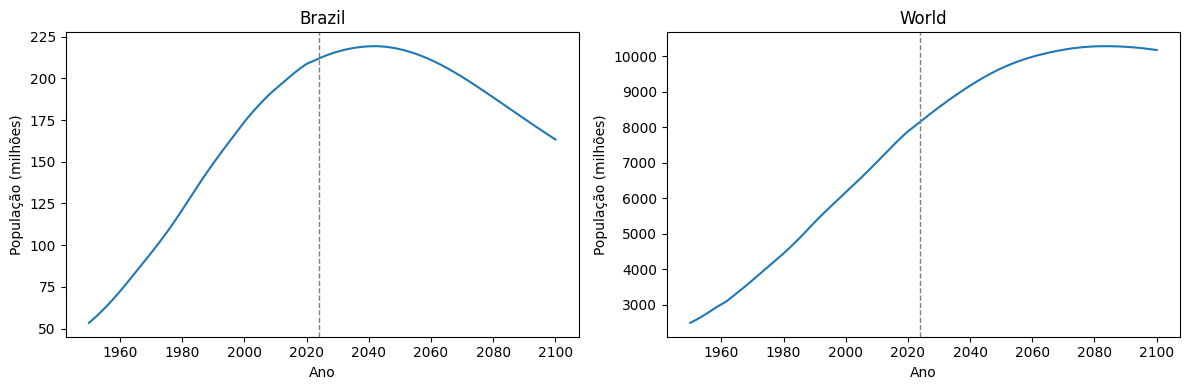

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, nome in zip(axes, ["Brazil", "World"]):
    s = df[df["Location"] == nome].set_index("Time")["TPopulation1July"]
    ax.plot(s.index, s / 1000)
    ax.axvline(2024, color="gray", ls="--", lw=1)
    ax.set(title=nome, xlabel="Ano", ylabel="População (milhões)")
plt.tight_layout()

## Exemplo: fecundidade (TFR) × expectativa de vida (LEx) em 2024, por país

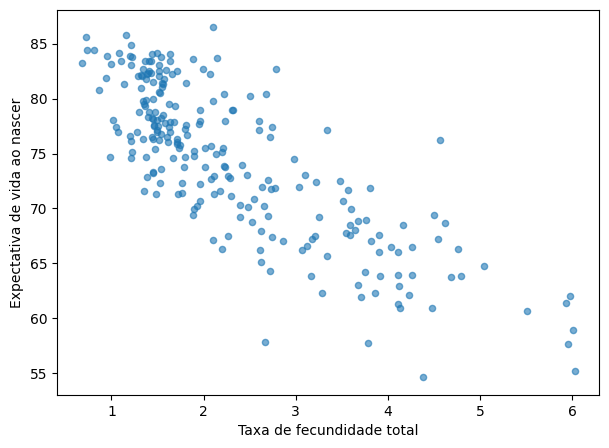

In [24]:
d = paises(df[df["Time"] == 2024])
ax = d.plot.scatter(x="TFR", y="LEx", alpha=0.6, figsize=(7, 5))
ax.set(xlabel="Taxa de fecundidade total", ylabel="Expectativa de vida ao nascer");